# INITIAL EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

# Load the data
games = pd.read_csv('DAC/data/games.csv')
pbp = pd.read_parquet('DAC/data/pbp.parquet')
player_games = pd.read_csv('DAC/data/player_games.csv')
tracking = pd.read_parquet('DAC/data/tracking.parquet')

### Basic Structure (shapes and columns)

In [2]:
datasets = {
    "pbp": pbp,
    "tracking": tracking,
    "games": games,
    "player_games": player_games
}

for name, df in datasets.items():
    print("\n" + "="*60)
    print(name.upper())
    print("="*60)
    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())


PBP
Shape: (63456, 37)

Columns:
['game_id', 'date', 'home_abbr', 'away_abbr', 'period', 'game_time', 'frame', 'score_differential', 'manpower_situation', 'team_n_skaters', 'team_f_ids', 'team_d_ids', 'team_g_id', 'opp_n_skaters', 'opp_f_ids', 'opp_d_ids', 'opp_g_id', 'player_id', 'player_position', 'event_team', 'team_in_possession', 'team_on_defense', 'is_possession_event', 'is_defensive_event', 'is_possession_breaking', 'is_last_play_of_possession', 'name', 'type', 'shorthand', 'outcome', 'flags', 'x_coord', 'y_coord', 'x_adj_coord', 'y_adj_coord', 'zone', 'play_section']

TRACKING
Shape: (12458760, 16)

Columns:
['game_id', 'period', 'gt_ms', 'jersey', 'track_id', 'track_team', 'identity_confidence', 'motion_confidence', 'x', 'y', 'velocity_x', 'velocity_y', 'velocity_magnitude', 'acceleration_x', 'acceleration_y', 'acceleration_magnitude']

GAMES
Shape: (19, 10)

Columns:
['game_id', 'game_date', 'away_team_id', 'home_team_id', 'away_team_loc', 'away_team_name', 'away_team_short'

### Missing Values

In [3]:
for name, df in datasets.items():
    print("\n" + "="*60)
    print(name.upper())
    print("="*60)

    missing = (
        df.isna()
          .mean()
          .sort_values(ascending=False)
          .rename("pct_missing")
    )

    print(missing[missing > 0].head(50))


PBP
manpower_situation    0.043621
play_section          0.043621
zone                  0.043621
player_position       0.043621
x_adj_coord           0.038720
outcome               0.038720
y_adj_coord           0.038720
y_coord               0.038720
score_differential    0.038720
player_id             0.038720
x_coord               0.038720
team_d_ids            0.014514
team_f_ids            0.013931
team_g_id             0.013048
opp_g_id              0.009881
opp_d_ids             0.006382
event_team            0.006178
opp_f_ids             0.006099
team_n_skaters        0.000016
opp_n_skaters         0.000016
Name: pct_missing, dtype: float64

TRACKING
jersey    0.013695
Name: pct_missing, dtype: float64

GAMES
Series([], Name: pct_missing, dtype: float64)

PLAYER_GAMES
role    1.0
Name: pct_missing, dtype: float64


In [4]:
# Specifically check possessione event player ids. Make sure no selection bias.
poss_only = pbp[pbp['is_possession_event']]

print(f"Total possession events: {len(poss_only)}")
print(f"Missing player_id among possession events: "
      f"{poss_only['player_id'].isna().mean():.2%}")

print("\nMissing player_id by event type (possession events only):")
print(
    poss_only[poss_only['player_id'].isna()]
    ['name'].value_counts()
)

Total possession events: 43725
Missing player_id among possession events: 0.00%

Missing player_id by event type (possession events only):
Series([], Name: count, dtype: int64)


### Data Types

In [5]:
for name, df in datasets.items():
    print("\n" + "="*60)
    print(name.upper())
    print("="*60)

    print(df.dtypes.sort_index())


PBP
away_abbr                      object
date                           object
event_team                     object
flags                          object
frame                           int32
game_id                         int32
game_time                     float64
home_abbr                      object
is_defensive_event               bool
is_last_play_of_possession       bool
is_possession_breaking           bool
is_possession_event              bool
manpower_situation             object
name                           object
opp_d_ids                      object
opp_f_ids                      object
opp_g_id                       object
opp_n_skaters                 float64
outcome                        object
period                          int32
play_section                   object
player_id                      object
player_position                object
score_differential            float64
shorthand                      object
team_d_ids                     object
team_f_

### Event Info

The play-by-play data contains a large number of hockey-specific event types. Before constructing any possession-value framework, it is important to understand which events represent player actions, which represent possession changes, and which are contextual or bookkeeping events.

In [6]:
for col in ["name", "type", "shorthand", "outcome"]:

    if col in pbp.columns:
        print("\n" + "="*50)
        print(col)
        print("="*50)

        print(
            pbp[col]
            .value_counts(dropna=False)
            .head(100)
        )


name
name
pass                      13290
lpr                       12509
reception                  9870
carry                      3850
failedpasslocation         3401
faceoff                    3166
puckprotection             2517
block                      2413
shot                       2009
pressure                   2006
controlledentryagainst     1413
check                      1399
dumpout                    1166
dumpin                      997
whistle                     928
dumpinagainst               919
penalty                     497
goal                        247
assist                      187
controlledbreakout          161
penaltydrawn                154
icing                       132
receptionprevention         110
offside                      66
penaltyshot                   8
solpr                         7
soshot                        7
socarry                       7
teamwithozonright             5
sogoal                        4
pscarry                      

In [7]:
# Possession-related fields

possession_cols = [
    "is_possession_event",
    "is_possession_breaking",
    "is_last_play_of_possession"
]

for col in possession_cols:
    print("\n" + "="*50)
    print(col)
    print("="*50)

    print(
        pbp[col]
        .value_counts(dropna=False)
    )


is_possession_event
is_possession_event
True     43725
False    19731
Name: count, dtype: int64

is_possession_breaking
is_possession_breaking
False    59700
True      3756
Name: count, dtype: int64

is_last_play_of_possession
is_last_play_of_possession
False    53694
True      9762
Name: count, dtype: int64


### Examine coordinate info

In [8]:
pbp[["x_coord", "y_coord"]].describe()

,x_coord,y_coord
count,60999.000000,60999.000000
mean,3.763696,1.082645
std,60.886188,26.146826
min,-99.285200,-42.500000
25%,-50.478664,-22.382353
50%,4.831482,0.756409
75%,59.652070,24.391174
max,99.907650,41.994118


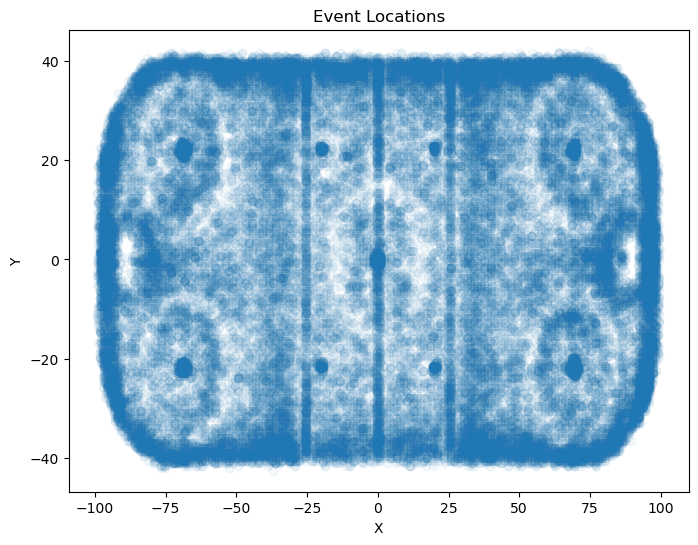

In [9]:
plt.figure(figsize=(8,6))

plt.scatter(
    pbp["x_coord"],
    pbp["y_coord"],
    alpha=0.05
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Event Locations")
plt.show()

### Tracking Overview

In [10]:
# Tracking player coverage
tracking.isna().mean().sort_values(ascending=False).head(50)

jersey                    0.013695
game_id                   0.000000
period                    0.000000
gt_ms                     0.000000
track_id                  0.000000
track_team                0.000000
identity_confidence       0.000000
motion_confidence         0.000000
x                         0.000000
y                         0.000000
velocity_x                0.000000
velocity_y                0.000000
velocity_magnitude        0.000000
acceleration_x            0.000000
acceleration_y            0.000000
acceleration_magnitude    0.000000
dtype: float64

In [11]:
tracking[
    [
        "identity_confidence",
        "motion_confidence"
    ]
].apply(pd.Series.value_counts)

,identity_confidence,motion_confidence
HIGH,11273928,12282555
LOW,1184832,176205


In [12]:
tracking.groupby(
    ["identity_confidence", "motion_confidence"]
).size()

identity_confidence  motion_confidence
HIGH                 HIGH                 11183170
                     LOW                     90758
LOW                  HIGH                  1099385
                     LOW                     85447
dtype: int64

In [13]:
# Num. of tracked players per game (make sure reasonable)
player_col = None

for c in tracking.columns:
    if "jersey" in c.lower():
        player_col = c
        break

tracking.groupby("game_id")[player_col].nunique()

game_id
171065    29
171073    27
171074    28
171075    27
171080    27
171081    29
171082    29
171083    30
171084    28
171085    27
171086    24
171087    28
171088    29
186400    25
186401    27
186402    29
186403    29
186910    29
186911    26
Name: jersey, dtype: int64

### Event Frequency Table

In [14]:
event_summary = (
    pbp["name"]
    .value_counts()
    .reset_index()
)

event_summary.columns = ["event", "count"]

event_summary["pct"] = (
    event_summary["count"]
    / event_summary["count"].sum()
)

event_summary

,event,count,pct
0,pass,13290,0.209436
1,lpr,12509,0.197129
2,reception,9870,0.155541
3,carry,3850,0.060672
4,failedpasslocation,3401,0.053596
5,faceoff,3166,0.049893
6,puckprotection,2517,0.039665
7,block,2413,0.038026
8,shot,2009,0.031660
9,pressure,2006,0.031612


### Check Reliability of Possession-End Flag

In [15]:
pbp["is_last_play_of_possession"].value_counts()

is_last_play_of_possession
False    53694
True      9762
Name: count, dtype: int64

In [16]:
# Check simple counts of the binary possession flags
for col in [
    "is_possession_event",
    "is_possession_breaking",
    "is_last_play_of_possession"
]:
    print(pbp[col].value_counts())

is_possession_event
True     43725
False    19731
Name: count, dtype: int64
is_possession_breaking
False    59700
True      3756
Name: count, dtype: int64
is_last_play_of_possession
False    53694
True      9762
Name: count, dtype: int64


In [17]:
# Examine actual possession-ending events by type
pd.crosstab(
    pbp["name"],
    pbp["is_last_play_of_possession"]
).sort_values(True, ascending=False)

is_last_play_of_possession,False,True
name,,
pass,9580,3710
puckprotection,696,1821
shot,580,1429
dumpout,77,1089
dumpinagainst,233,686
reception,9545,325
dumpin,790,207
lpr,12321,188
goal,128,119


In [18]:
# Now expand to all possession events
pd.crosstab(
    pbp["name"],
    pbp["is_possession_event"]
).sort_values(True, ascending=False)

is_possession_event,False,True
name,,
pass,0,13290
lpr,2636,9873
reception,0,9870
carry,0,3850
puckprotection,0,2517
shot,0,2009
dumpout,0,1166
dumpin,0,997
goal,128,119


### Look at One Example Possession

In [19]:
idx = pbp.index[pbp["is_last_play_of_possession"]][0]

pbp.iloc[idx-5:idx+8][[
    "game_time",
    "team_in_possession",
    "name",
    "outcome",
    "is_possession_event",
    "is_last_play_of_possession"
]]

,game_time,team_in_possession,name,outcome,is_possession_event,is_last_play_of_possession
2,0.000000,None,faceoff,failed,False,False
3,0.166667,USA Team USA,lpr,successful,True,False
4,0.166667,USA Team USA,lpr,failed,False,False
5,0.900000,USA Team USA,pass,successful,True,False
6,1.733333,USA Team USA,reception,successful,True,False
7,2.333333,USA Team USA,pass,failed,True,True
8,2.833333,USA Team USA,block,successful,False,False
9,2.833333,USA Team USA,failedpasslocation,failed,False,False
10,3.666667,USA Team USA,offside,failed,False,False
11,4.033333,USA Team USA,whistle,None,False,False


### Possession Length Check

In [20]:
pbp = pbp.sort_values(
    ["game_id","period","game_time"]
).copy()

pbp["possession_change"] = (
    (pbp["game_id"] != pbp["game_id"].shift())
    |
    (
        pbp["team_in_possession"]
        !=
        pbp["team_in_possession"].shift()
    )
)

pbp["possession_id"] = (
    pbp["possession_change"]
    .cumsum()
)

(
    pbp.loc[pbp["is_possession_event"]]
       .groupby("possession_id")
       .size()
       .describe()
)

count    6878.000000
mean        6.357226
std         5.918172
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max        86.000000
dtype: float64

Key Findings

- team_in_possession directly identifies possession ownership.
- is_last_play_of_possession appears reliable for identifying possession-ending events.
- Possession events are clearly separated from contextual events.
- Event locations are available through x_coord and y_coord.
- Tracking quality appears sufficient for supplementary analysis despite expected coverage gaps.
- The available data supports construction of a possession-value framework for evaluating puck management.